In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from bidi.algorithm import get_display
import arabic_reshaper

In [2]:
df_bra = pd.read_csv(r'D:\HVIA\cotonil\data\branches.csv',parse_dates=['opening_date'])


In [3]:
df_bra.describe()

,opening_date
count,80
mean,2019-09-01 09:36:00
min,2018-11-06 00:00:00
25%,2019-04-27 06:00:00
50%,2019-08-17 12:00:00
75%,2020-01-22 12:00:00
max,2020-08-29 00:00:00


In [4]:
df_bra.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 80 entries, 0 to 79
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   branch_id             80 non-null     object        
 1   branch_name_ar        80 non-null     object        
 2   governorate_ar        80 non-null     object        
 3   city_ar               80 non-null     object        
 4   address_ar            80 non-null     object        
 5   retail_location_type  80 non-null     object        
 6   opening_date          80 non-null     datetime64[ns]
dtypes: datetime64[ns](1), object(6)
memory usage: 4.5+ KB


In [5]:
print("Number of unique branches:", df_bra['branch_id'].nunique())

Number of unique branches: 80


In [6]:
values_counts_based_on_year = df_bra['opening_date'].dt.year.value_counts().sort_index()

(array([2018, 2019, 2020]),
 [Text(2018, 0, '2018'), Text(2019, 0, '2019'), Text(2020, 0, '2020')])

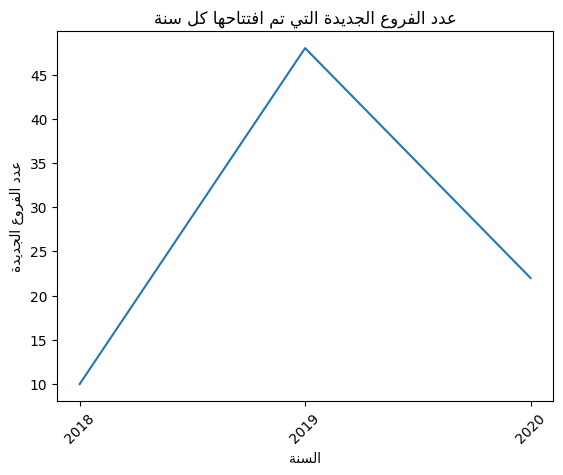

In [7]:
sns.lineplot(x=values_counts_based_on_year.index, y=values_counts_based_on_year.values)
plt.title(get_display(arabic_reshaper.reshape('عدد الفروع الجديدة التي تم افتتاحها كل سنة')))
plt.xlabel(get_display(arabic_reshaper.reshape('السنة')))
plt.ylabel(get_display(arabic_reshaper.reshape('عدد الفروع الجديدة')))
plt.xticks(np.arange(2018, 2021, 1))
plt.xticks(rotation=45)

In [8]:
new_branches = (
    df_bra['opening_date']
    .dt.year
    .value_counts()
    .sort_index()
)

cum_branches = new_branches.cumsum()

In [37]:
cum_branches

opening_date
2018    10
2019    58
2020    80
Name: count, dtype: int64

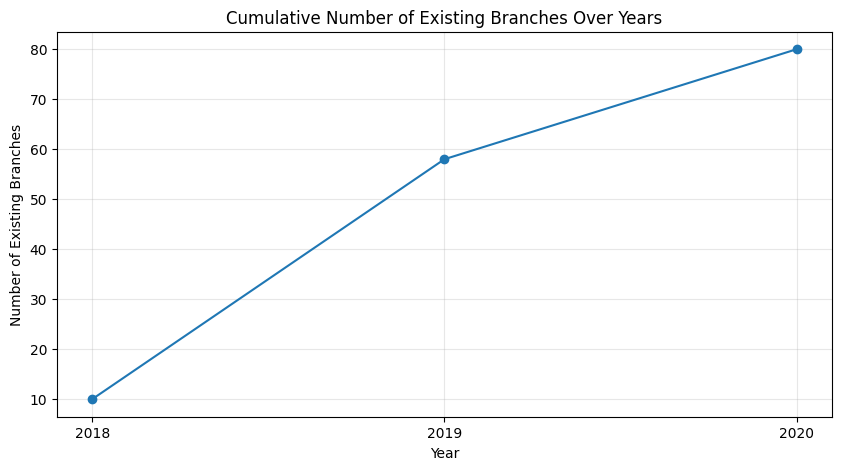

In [9]:
plt.figure(figsize=(10, 5))

plt.plot(
    cum_branches.index,
    cum_branches.values,
    marker='o'
)

plt.xticks(cum_branches.index.astype(int))
plt.xlabel('Year')
plt.ylabel('Number of Existing Branches')
plt.title('Cumulative Number of Existing Branches Over Years')

plt.grid(alpha=0.3)
plt.show()

In [10]:
print("Number of unique government :", df_bra['governorate_ar'].nunique())

Number of unique government : 21


In [34]:
df_bra['opening_year'] = df_bra['opening_date'].dt.year
df_bra ['count'] = df_bra.groupby('opening_year')['branch_id'].transform('count')


In [11]:
df_bra.governorate_ar.unique()

array(['القاهرة', 'الجيزة', 'الإسكندرية', 'الدقهلية', 'الإسماعيلية',
       'البحيرة', 'مطروح', 'الشرقية', 'الغربية', 'البحر الأحمر', 'الفيوم',
       'المنوفية', 'المنيا', 'بني سويف', 'بورسعيد', 'دمياط', 'سوهاج',
       'قنا', 'كفر الشيخ', 'أسوان', 'أسيوط'], dtype=object)

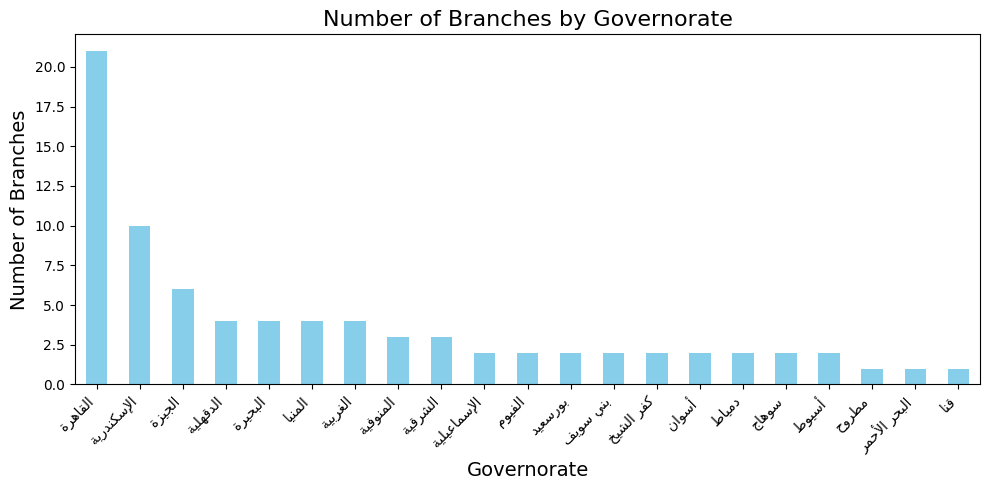

In [12]:
dic_br = df_bra['governorate_ar'].value_counts()
dic_br.index = [
    get_display(arabic_reshaper.reshape(str(name)))
    for name in dic_br.index
]

dic_br.plot(kind='bar', figsize=(10, 5), color='skyblue')

plt.title('Number of Branches by Governorate', fontsize=16)
plt.xlabel('Governorate', fontsize=14)
plt.ylabel('Number of Branches', fontsize=14)

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

<Axes: >

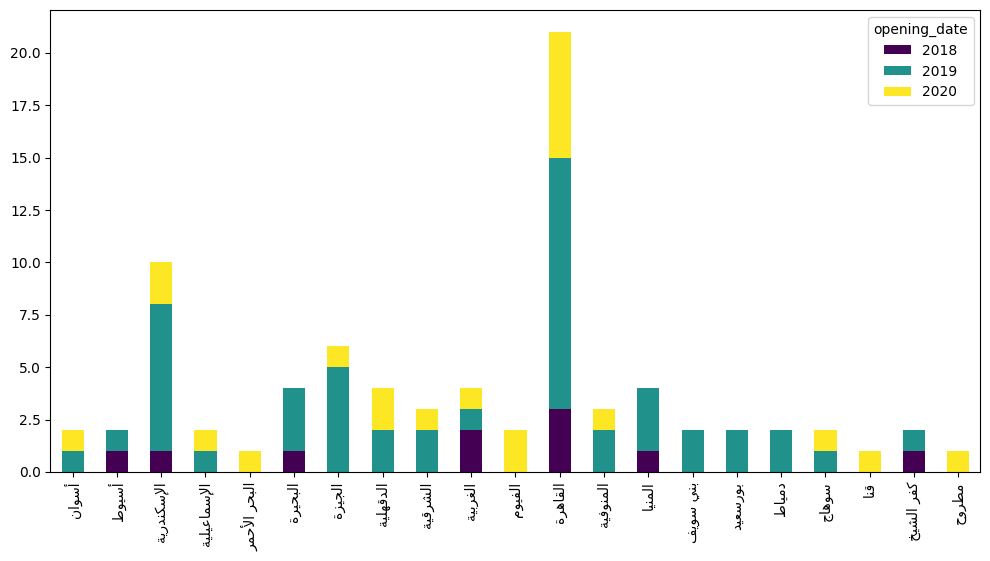

In [13]:
dist_y = df_bra.groupby(['governorate_ar', df_bra['opening_date'].dt.year])['branch_id'].count().unstack(fill_value=0)
dist_y.index = [
    get_display(arabic_reshaper.reshape(str(name)))
    for name in dist_y.index
]

dist_y.plot(kind='bar', stacked=True, figsize=(12, 6), colormap='viridis')

In [14]:
governorate_mapping = {
    'القاهرة': 'Cairo',
    'الجيزة': 'Giza',
    'الإسكندرية': 'Alexandria',
    'الدقهلية': 'Dakahlia',
    'الإسماعيلية': 'Ismailia',
    'البحيرة': 'Beheira',
    'مطروح': 'Matrouh',
    'الشرقية': 'Sharqia',
    'الغربية': 'Gharbia',
    'البحر الأحمر': 'Red Sea',
    'الفيوم': 'Faiyum',
    'المنوفية': 'Monufia',
    'المنيا': 'Minya',
    'بني سويف': 'Beni Suef',
    'بورسعيد': 'Port Said',
    'دمياط': 'Damietta',
    'سوهاج': 'Sohag',
    'قنا': 'Qena',
    'كفر الشيخ': 'Kafr El Sheikh',
    'أسوان': 'Aswan',
    'أسيوط': 'Assiut'
}

df_bra['governorate_en'] = df_bra['governorate_ar'].map(governorate_mapping)

In [15]:
import plotly.express as px
import arabic_reshaper
from bidi.algorithm import get_display

# Count newly opened branches
dist_y = (
    df_bra.groupby([
        'governorate_en',
        df_bra['opening_date'].dt.year
    ])['branch_id']
    .count()
    .unstack(fill_value=0)
)

# Include all years
all_years = range(
    df_bra['opening_date'].dt.year.min(),
    df_bra['opening_date'].dt.year.max() + 1
)

dist_y = dist_y.reindex(columns=all_years, fill_value=0)

# Cumulative branches
dist_y_cumulative = dist_y.cumsum(axis=1)



# Plot
fig = px.bar(
    dist_y_cumulative,
    x=dist_y_cumulative.index,
    y=dist_y_cumulative.columns,
    barmode='stack',
    labels={
        'x': 'Governorate',
        'value': 'Number of Branches',
        'variable': 'Year'
    },
    title='Cumulative Existing Branches by Governorate',
    color_discrete_sequence=px.colors.qualitative.Dark24
)

fig.update_layout(
    template='plotly_white',
    width=1300,
    height=700,
    font=dict(
        family='Arial',
        size=13
    ),
    title=dict(
        x=0.5,
        xanchor='center'
    ),
    xaxis=dict(
        title='المحافظة',
        tickangle=-45
    ),
    yaxis=dict(
        title='عدد الفروع',
        rangemode='tozero'
    ),
    legend=dict(
        title='Opening Year',
        orientation='h',
        yanchor='bottom',
        y=1.02,
        xanchor='center',
        x=0.5
    )
)

fig.show()

In [16]:
from egygeo import get_coordinates

df_bra["governorate_en"] = df_bra["governorate_en"].str.strip()

df_bra[["latitude", "longitude"]] = df_bra["governorate_en"].apply(
    lambda name: pd.Series(get_coordinates(name))
)


In [17]:
import folium
import pandas as pd
from IPython.display import display

# 1. Get the latest year
latest_year = df_bra['opening_date'].dt.year.max()

# 2. Group branches by governorate
governorate_branches = (
    df_bra[df_bra['opening_date'].dt.year <= latest_year]
    .groupby('governorate_en')
    .agg(
        branch_count=('branch_id', 'nunique'),
        latitude=('latitude', 'first'),
        longitude=('longitude', 'first')
    )
    .reset_index()
)

# 3. Create map
m = folium.Map(
    location=[26.8, 30.8],
    zoom_start=6,
    tiles='OpenStreetMap'
)

# 4. Add proportional bubbles
max_branches = governorate_branches['branch_count'].max()

for _, row in governorate_branches.iterrows():

    ratio = row['branch_count'] / max_branches

    folium.CircleMarker(
        location=[row['latitude'], row['longitude']],
        radius=8 + ratio * 22,
        color='#800000',
        weight=1.5,
        fill=True,
        fill_color='#B30000',
        fill_opacity=0.3 + ratio * 0.65,
        tooltip=f"{row['governorate_en']}: {row['branch_count']} branches",
        popup=f"""
            <b>Governorate:</b> {row['governorate_en']}<br>
            <b>Existing Branches:</b> {row['branch_count']}
        """
    ).add_to(m)



In [18]:
m

In [19]:
df_cus = pd.read_csv(r'D:\HVIA\cotonil\data\customers.csv',parse_dates=['joined_date'])

In [20]:
df_cus.head()

,customer_id,customer_segment,customer_name_ar,governorate_ar,joined_date,age_band
0,C0000001,Retail,كريم حمادة,دمياط,2018-10-19,55+
1,C0000002,Retail,مريم خليل,أسوان,2018-10-19,18-24
2,C0000003,Retail,خالد محمد,القاهرة,2018-10-19,45-54
3,C0000004,Retail,أحمد منصور,المنوفية,2018-10-19,35-44
4,C0000005,Retail,رانيا إبراهيم,المنوفية,2018-10-19,18-24


In [21]:
df_cus.info()   

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 85000 entries, 0 to 84999
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   customer_id       85000 non-null  object        
 1   customer_segment  85000 non-null  object        
 2   customer_name_ar  85000 non-null  object        
 3   governorate_ar    85000 non-null  object        
 4   joined_date       85000 non-null  datetime64[ns]
 5   age_band          85000 non-null  object        
dtypes: datetime64[ns](1), object(5)
memory usage: 3.9+ MB


In [22]:
df_cus.describe()

,joined_date
count,85000
mean,2022-10-18 11:35:15.952941568
min,2018-10-19 00:00:00
25%,2020-10-18 00:00:00
50%,2022-10-18 12:00:00
75%,2024-10-18 00:00:00
max,2026-10-18 00:00:00


In [23]:
print("Number of unique customers:", df_cus['customer_id'].nunique())

Number of unique customers: 85000


C:\Users\Mmahm\AppData\Local\Temp\ipykernel_3224\2036823331.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=dic.index, x=dic.values, palette='viridis')


Text(0, 0.5, 'Governorate')

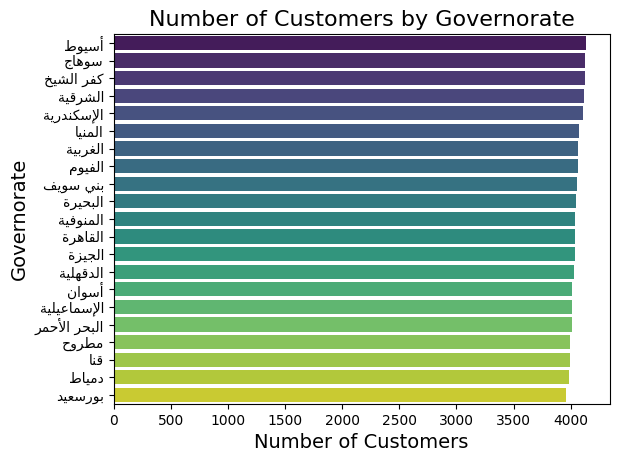

In [24]:
dic = df_cus['governorate_ar'].value_counts().sort_values(ascending=False)
dic.index = [
    get_display(arabic_reshaper.reshape(str(name)))
    for name in dic.index
]

sns.barplot(y=dic.index, x=dic.values, palette='viridis')
plt.title('Number of Customers by Governorate', fontsize=16)
plt.xlabel('Number of Customers', fontsize=14)
plt.ylabel('Governorate', fontsize=14)


In [25]:
governorate_mapping = {
    'القاهرة': 'Cairo',
    'الجيزة': 'Giza',
    'الإسكندرية': 'Alexandria',
    'الدقهلية': 'Dakahlia',
    'الإسماعيلية': 'Ismailia',
    'البحيرة': 'Beheira',
    'مطروح': 'Matrouh',
    'الشرقية': 'Sharqia',
    'الغربية': 'Gharbia',
    'البحر الأحمر': 'Red Sea',
    'الفيوم': 'Faiyum',
    'المنوفية': 'Monufia',
    'المنيا': 'Minya',
    'بني سويف': 'Beni Suef',
    'بورسعيد': 'Port Said',
    'دمياط': 'Damietta',
    'سوهاج': 'Sohag',
    'قنا': 'Qena',
    'كفر الشيخ': 'Kafr El Sheikh',
    'أسوان': 'Aswan',
    'أسيوط': 'Assiut'
}

df_cus['governorate_en'] = df_cus['governorate_ar'].map(governorate_mapping)

In [26]:
from egygeo import get_coordinates
df_cus["governorate_en"] = df_cus["governorate_en"].str.strip()
df_cus[["latitude", "longitude"]] = df_cus["governorate_en"].apply(
    lambda name: pd.Series(get_coordinates(name)) )


In [27]:
import folium
import pandas as pd
from IPython.display import display

# 1. Clean governorate names
df_cus["governorate_en"] = df_cus["governorate_en"].str.strip()

# 2. Aggregate customers
governorate_customers = (
    df_cus.groupby("governorate_en")
    .agg(
        customer_count=("customer_id", "nunique"),
        latitude=("latitude", "first"),
        longitude=("longitude", "first")
    )
    .reset_index()
)

# 3. Create map
m = folium.Map(
    location=[26.8, 30.8],
    zoom_start=6,
    tiles="OpenStreetMap"
)

# 4. Add proportional bubbles
max_customers = governorate_customers["customer_count"].max()

for _, row in governorate_customers.iterrows():

    ratio = row["customer_count"] / max_customers

    folium.CircleMarker(
        location=[row["latitude"], row["longitude"]],
        radius=6 + 24 * (ratio ** 0.5),
        color="#003B73",
        weight=1.5,
        fill=True,
        fill_color="#0077B6",
        fill_opacity=0.65,
        tooltip=f"{row['governorate_en']}: {row['customer_count']:,} customers",
        popup=f"""
            <b>Governorate:</b> {row['governorate_en']}<br>
            <b>Customers:</b> {row['customer_count']:,}
        """
    ).add_to(m)

display(m)

<Axes: xlabel='year_joined'>

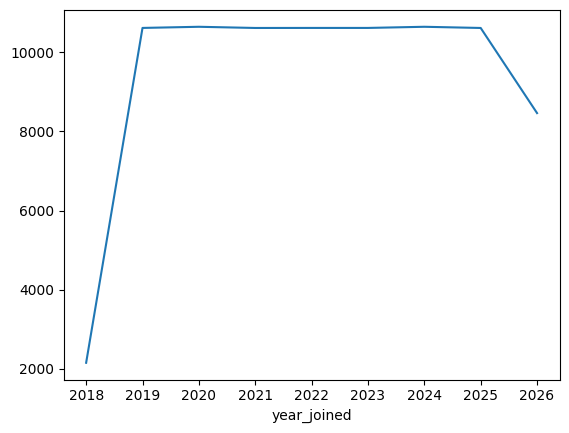

In [28]:
df_cus['year_joined'] = df_cus['joined_date'].dt.year
customer_counts_by_year = df_cus['year_joined'].value_counts().sort_index()
sns.lineplot(x=customer_counts_by_year.index, y=customer_counts_by_year.values)

Text(0.5, 1.0, 'Customer Segments Distribution')

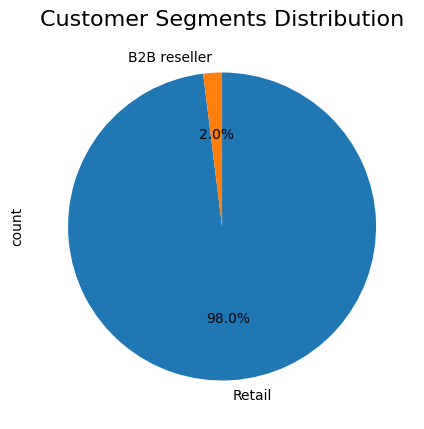

In [29]:
df_cus['customer_segment'].value_counts().plot(kind='pie', figsize=(10, 5), color='lightgreen',
                                                autopct='%1.1f%%', startangle=90, counterclock=False)
plt.title('Customer Segments Distribution', fontsize=16)

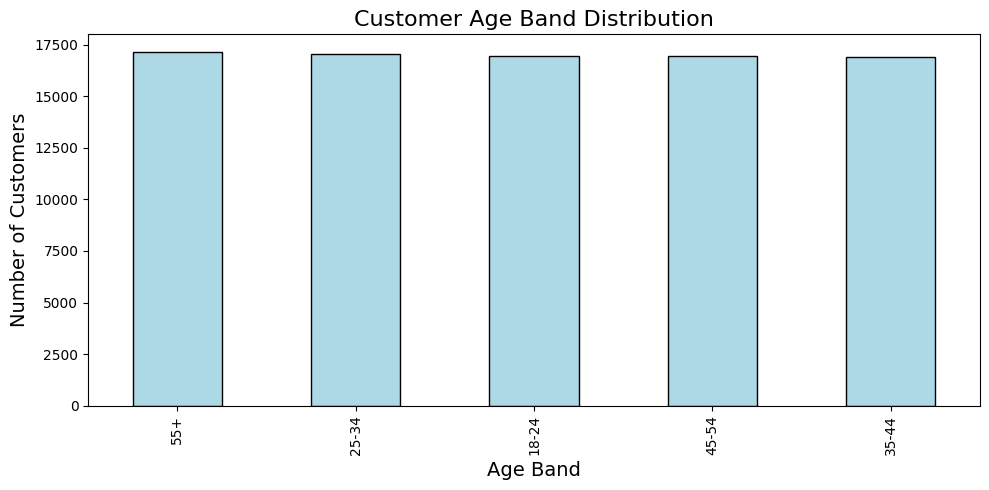

In [32]:
df_cus['age_band'].value_counts().plot(kind='bar', figsize=(10, 5), color='lightblue', edgecolor='black')
plt.title('Customer Age Band Distribution', fontsize=16)
plt.xlabel('Age Band', fontsize=14)
plt.ylabel('Number of Customers', fontsize=14)
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [30]:
# Customers per governorate
governorate_customers = (
    df_cus.groupby("governorate_en")
    .agg(customer_count=("customer_id", "nunique"))
    .reset_index()
)

# Branches per governorate
governorate_branches = (
    df_bra.groupby("governorate_en")
    .agg(
        branch_count=("branch_id", "nunique"),
        latitude=("latitude", "first"),
        longitude=("longitude", "first")
    )
    .reset_index()
)

# Merge both datasets
governorate_data = governorate_branches.merge(
    governorate_customers,
    on="governorate_en",
    how="left"
)

governorate_data["customer_count"] = (
    governorate_data["customer_count"].fillna(0)
)

In [31]:

import folium
import pandas as pd
import branca.colormap as cm

from egygeo import get_boundary, list_governorates
from IPython.display import display

# ==========================================
# 1. Standardize governorate names
# ==========================================

def get_canonical_name(name):
    feature = get_boundary(name, as_feature=True)

    if feature is None:
        return None

    return feature["properties"]["Subdivision_en"]


df_bra["governorate_en"] = df_bra["governorate_en"].str.strip()
df_cus["governorate_en"] = df_cus["governorate_en"].str.strip()

df_bra["governorate_key"] = df_bra["governorate_en"].apply(
    get_canonical_name
)

df_cus["governorate_key"] = df_cus["governorate_en"].apply(
    get_canonical_name
)

# ==========================================
# 2. Aggregate branches
# ==========================================

branch_data = (
    df_bra.groupby("governorate_key")
    .agg(
        branch_count=("branch_id", "nunique"),
        latitude=("latitude", "first"),
        longitude=("longitude", "first")
    )
    .reset_index()
)

# ==========================================
# 3. Aggregate customers
# ==========================================

customer_data = (
    df_cus.groupby("governorate_key")
    .agg(
        customer_count=("customer_id", "nunique")
    )
    .reset_index()
)

# ==========================================
# 4. Merge both datasets
# ==========================================

governorate_data = branch_data.merge(
    customer_data,
    on="governorate_key",
    how="outer"
)

governorate_data[["branch_count", "customer_count"]] = (
    governorate_data[["branch_count", "customer_count"]]
    .fillna(0)
)

# ==========================================
# 5. Create governorates GeoJSON
# ==========================================

features = []

for gov in list_governorates():

    feature = get_boundary(gov["english"], as_feature=True)

    if feature is None:
        continue

    gov_name = feature["properties"]["Subdivision_en"]

    gov_data = governorate_data[
        governorate_data["governorate_key"] == gov_name
    ]

    customer_count = (
        int(gov_data["customer_count"].iloc[0])
        if not gov_data.empty else 0
    )

    branch_count = (
        int(gov_data["branch_count"].iloc[0])
        if not gov_data.empty else 0
    )

    feature["properties"]["customer_count"] = customer_count
    feature["properties"]["branch_count"] = branch_count

    features.append(feature)


egypt_geojson = {
    "type": "FeatureCollection",
    "features": features
}

# ==========================================
# 6. Create map
# ==========================================

m = folium.Map(
    location=[26.8, 30.8],
    zoom_start=6,
    tiles="OpenStreetMap"
)

# ==========================================
# 7. Red Choropleth - Customers
# ==========================================

max_customers = max(
    1,
    governorate_data["customer_count"].max()
)

customer_colormap = cm.LinearColormap(
    colors=[
        "#FFF0F0",
        "#FFB3B3",
        "#FF6666",
        "#CC0000",
        "#800000"
    ],
    vmin=0,
    vmax=max_customers,
    caption="Number of Customers"
)

folium.GeoJson(
    egypt_geojson,

    style_function=lambda feature: {
        "fillColor": customer_colormap(
            feature["properties"]["customer_count"]
        ),
        "color": "#FFFFFF",
        "weight": 1.2,
        "fillOpacity": 0.8
    },

    tooltip=folium.GeoJsonTooltip(
        fields=[
            "Subdivision_en",
            "customer_count",
            "branch_count"
        ],
        aliases=[
            "Governorate:",
            "Customers:",
            "Branches:"
        ],
        sticky=True
    )

).add_to(m)

customer_colormap.add_to(m)

# ==========================================
# 8. Blue Bubbles - Branches
# ==========================================

max_branches = max(
    1,
    governorate_data["branch_count"].max()
)

for _, row in governorate_data.iterrows():

    if pd.isna(row["latitude"]) or pd.isna(row["longitude"]):
        continue

    ratio = row["branch_count"] / max_branches

    folium.CircleMarker(
        location=[
            row["latitude"],
            row["longitude"]
        ],

        radius=6 + 22 * (ratio ** 0.5),

        color="#003B73",
        weight=1.5,

        fill=True,
        fill_color="#0077B6",
        fill_opacity=0.85,

        tooltip=(
            f"{row['governorate_key']} | "
            f"{int(row['branch_count']):,} Branches"
        ),

        popup=f"""
            <b>Governorate:</b> {row['governorate_key']}<br>
            <b>Branches:</b> {int(row['branch_count']):,}<br>
            <b>Customers:</b> {int(row['customer_count']):,}
        """

    ).add_to(m)

# ==========================================
# 9. Display map
# ==========================================

display(m)
